<a href="https://colab.research.google.com/github/hilduAgl/brain-age-eeg/blob/main/cnn_multisegment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Set up environment

In [12]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import mean_absolute_error, mean_squared_error

DATA_DIR = Path("/content/drive/MyDrive/BrainAge/data")
RESULTS_DIR = Path("/content/drive/MyDrive/BrainAge/results")
CHECKPOINT_PATH = Path("/content/drive/MyDrive/BrainAge/cnn_best.pth")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Checkpoint exists:", CHECKPOINT_PATH.exists())
print("Data exists:", DATA_DIR.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cpu
Checkpoint exists: True
Data exists: True


In [19]:
assert FS == 64
assert DURATION == 8
assert N_SAMPLES == 512
assert config["random_crop_train"] is True

print("Checkpoint configuration verified.")

Checkpoint configuration verified.


### Copy the CNN architecture

In [13]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=(1, 3), padding=(0, 1)
            ),
            nn.ReLU(),
            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=(1, 3), padding=(0, 1)
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(1, 2)),
        )

    def forward(self, x):
        return self.block(x)


class BrainAgeCNNFlat(nn.Module):
    def __init__(self, in_channels=20, n_samples=512):
        super().__init__()

        self.conv1 = ConvBlock(1, 32)
        self.conv2 = ConvBlock(32, 64)
        self.conv3 = ConvBlock(64, 128)

        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(
                128 * in_channels * (n_samples // 8), 128
            ),
            nn.ReLU(),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        if x.dim() == 3:
            x = x.unsqueeze(1)

        x = self.conv3(self.conv2(self.conv1(x)))
        return self.fc(x).squeeze(-1)

### Load the saved model

In [14]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)

config = checkpoint["config"]

FS = config["sampling_rate"]
DURATION = config["segment_duration"]
N_SAMPLES = config["n_samples"]

assert config["model_name"] == "flat"
assert config["in_channels"] == 20

model = BrainAgeCNNFlat(
    in_channels=config["in_channels"],
    n_samples=N_SAMPLES
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("CNN loaded successfully")
print("Window duration:", DURATION, "seconds")
print("Samples per window:", N_SAMPLES)

CNN loaded successfully
Window duration: 8 seconds
Samples per window: 512


### Extract multiple EEG windows
Each EEG file contains approximately 15 minutes of data. We want to select several 8-second sections spread evenly throughout the recording.

In [15]:
def extract_windows(eeg, n_windows, n_samples, single_start=None):
    total_samples = eeg.shape[1]

    if total_samples < n_samples:
        raise ValueError("EEG recording is too short")

    if n_windows == 1 and single_start is not None:
        # Reproduce the original CNN validation window
        starts = [int(single_start)]
    else:
        # Spread windows evenly across the recording
        starts = np.linspace(
            0,
            total_samples - n_samples,
            n_windows,
            dtype=int
        )

    windows = []

    for start in starts:
        window = eeg[:, start:start + n_samples]

        if window.shape != (20, n_samples):
            raise ValueError("Unexpected EEG window shape")

        windows.append(window.float())

    return torch.stack(windows)

### Create the prediction function
This function takes a child's full EEG recording, extracts the windows, runs the CNN and averages the predictions.

In [16]:
@torch.no_grad()
def predict_age(eeg, n_windows, single_start=None):
    windows = extract_windows(
        eeg,
        n_windows=n_windows,
        n_samples=N_SAMPLES,
        single_start=single_start
    ).to(device)

    predictions = model(windows)

    return predictions.mean().item()

### Run the experiment on all validation children
Now we load the same validation split used by your teammate.

In [10]:
val_segments = torch.load(
    DATA_DIR / "segments_h1k_val.pt",
    map_location="cpu",
    weights_only=False
)

print("Validation entries:", len(val_segments))

WINDOW_COUNTS = [1, 5, 10, 20]

results = []
all_predictions = {}

for n_windows in WINDOW_COUNTS:
    rows = []

    for entry in val_segments:
        filename = entry[4]
        actual_age = float(entry[3])

        eeg_path = (
            DATA_DIR / "pre_processed"
            / filename.replace(".edf", ".pt")
        )

        eeg = torch.load(
            eeg_path,
            map_location="cpu",
            weights_only=True
        )

        # Metadata start is in seconds
        original_start = int(float(entry[2]) * FS)

        predicted_age = predict_age(
            eeg,
            n_windows=n_windows,
            single_start=original_start if n_windows == 1 else None
        )

        rows.append({
            "filename": filename,
            "actual_age": actual_age,
            "predicted_age": predicted_age
        })

    df = pd.DataFrame(rows)

    assert len(df) == 103
    assert df["filename"].is_unique

    mae = mean_absolute_error(
        df["actual_age"],
        df["predicted_age"]
    )

    rmse = np.sqrt(mean_squared_error(
        df["actual_age"],
        df["predicted_age"]
    ))

    output_path = (
        RESULTS_DIR
        / f"cnn_flat_8s_{n_windows}windows_val_predictions.csv"
    )

    df.to_csv(output_path, index=False)

    all_predictions[n_windows] = df

    results.append({
        "Windows": n_windows,
        "MAE": mae,
        "RMSE": rmse
    })

    print(
        f"{n_windows} windows: "
        f"MAE={mae:.4f}, RMSE={rmse:.4f}"
    )

results_df = pd.DataFrame(results)
display(results_df)

Validation entries: 103
1 windows: MAE=1.4846, RMSE=2.1213
5 windows: MAE=1.3343, RMSE=1.8183
10 windows: MAE=1.3159, RMSE=1.7624
20 windows: MAE=1.2507, RMSE=1.6724


,Windows,MAE,RMSE
0,1,1.484553,2.121254
1,5,1.334268,1.818260
2,10,1.315850,1.762397
3,20,1.250708,1.672400


### Check results and make a plot

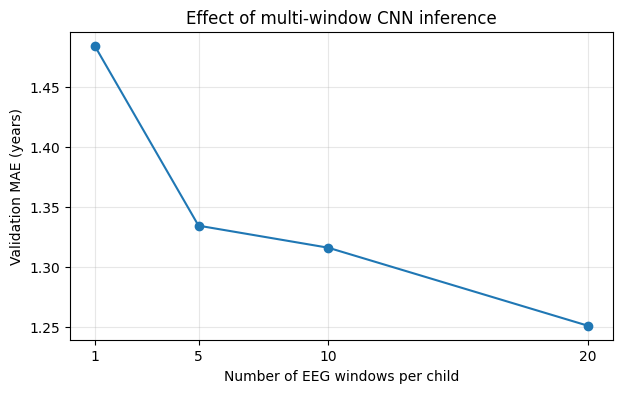

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.plot(
    results_df["Windows"],
    results_df["MAE"],
    marker="o"
)

plt.xlabel("Number of EEG windows per child")
plt.ylabel("Validation MAE (years)")
plt.title("Effect of multi-window CNN inference")
plt.xticks(WINDOW_COUNTS)
plt.grid(alpha=0.3)

plt.savefig(
    RESULTS_DIR / "cnn_multiwindow_mae.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Final Test Evaluation — 20 Windows

The number of inference windows was selected using validation MAE.
The best tested configuration was 20 evenly spaced 8-second windows.

We now evaluate this fixed configuration on the held-out test set.
The trained CNN weights and inference settings are unchanged.

In [17]:
# Final test evaluation: selected 20-window CNN

test_segments = torch.load(
    DATA_DIR / "segments_h1k_test.pt",
    map_location="cpu",
    weights_only=False
)

print("Test entries:", len(test_segments))

N_WINDOWS = 20

model.eval()
rows = []

for entry in test_segments:
    filename = entry[4]
    actual_age = float(entry[3])

    eeg_path = (
        DATA_DIR / "pre_processed"
        / filename.replace(".edf", ".pt")
    )

    eeg = torch.load(
        eeg_path,
        map_location="cpu",
        weights_only=True
    )

    predicted_age = predict_age(
        eeg,
        n_windows=N_WINDOWS
    )

    rows.append({
        "filename": filename,
        "actual_age": actual_age,
        "predicted_age": predicted_age
    })

cnn_test_df = pd.DataFrame(rows)

# Check test data integrity
assert len(cnn_test_df) == 104
assert cnn_test_df["filename"].is_unique
assert cnn_test_df.notna().all().all()

# Calculate final test metrics
cnn_test_mae = mean_absolute_error(
    cnn_test_df["actual_age"],
    cnn_test_df["predicted_age"]
)

cnn_test_rmse = np.sqrt(mean_squared_error(
    cnn_test_df["actual_age"],
    cnn_test_df["predicted_age"]
))

cnn_test_bias = (
    cnn_test_df["predicted_age"]
    - cnn_test_df["actual_age"]
).mean()

print("\nFinal CNN Test Results")
print(f"MAE:  {cnn_test_mae:.4f} years")
print(f"RMSE: {cnn_test_rmse:.4f} years")
print(f"Bias: {cnn_test_bias:+.4f} years")

# Save test predictions separately
output_path = (
    RESULTS_DIR
    / "cnn_flat_8s_20windows_test_predictions.csv"
)

cnn_test_df.to_csv(output_path, index=False)

print("\nSaved:", output_path)

display(cnn_test_df.head())

Test entries: 104

Final CNN Test Results
MAE:  1.0214 years
RMSE: 1.3416 years
Bias: +0.2090 years

Saved: /content/drive/MyDrive/BrainAge/results/cnn_flat_8s_20windows_test_predictions.csv


,filename,actual_age,predicted_age
0,C1M853.edf,0.501027,1.004204
1,23N88N.edf,3.513076,4.759491
2,8X681F.edf,0.584309,0.808893
3,D784V2.edf,13.091656,11.110502
4,BO5727.edf,7.419452,5.337014


In [18]:
val_filenames = {entry[4] for entry in val_segments}
test_filenames = set(cnn_test_df["filename"])

assert val_filenames.isdisjoint(test_filenames)

print("Validation and test subjects do not overlap.")

Validation and test subjects do not overlap.
